# YouTube Long-Form Video Performance Analysis
## Dr. Agustín Landívar — data audit, exploratory analysis and content categories
**Analyst:** Marco Antonio Cruz Rojas  
**Business stakeholder:** Dr. Agustín Landívar, channel owner and CEO. Marco reports that he presented recommendations and performance charts directly to him. This notebook documents a new analysis; its recommendations are proposals, not evidence of actions already implemented or measured impact.

**Framework:** PACE — Plan, Analyze, Construct, Execute.  
**Source:** `data/raw/500 VIDEO LIVES LARGOS.xlsx`. Original workbook is preserved.  
**Status:** Executed analytical draft. Category assignments are title-based proposals awaiting human review. Export filters, reporting period and video/live format remain unconfirmed.

### How to use this notebook
1. Place this notebook in `notebooks` and the source workbook in `data/raw` under the same project root.
2. Install `requirements.txt` into your virtual environment and select it as the notebook kernel.
3. Run cells from top to bottom. Figures and tables are regenerated in `images` and `data/processed`.
4. Review `data/processed/category_review.csv`. Fill `final_category` and set `review_status` to `Reviewed` only after checking the topic. Reruns preserve this file.
5. Change the metadata settings below when the export scope is confirmed. Do not use publication dates as a substitute for the reporting period.

Tables and chart commentary are generated from the data on every run. English documentation supports portfolio review; titles remain in their original Spanish.

# P — Plan
## 1. Business question and analytical scope
**Question:** Which content topics and video characteristics are associated with reach, viewing duration and estimated revenue among the exported videos?

The intended decisions are which topics to investigate for future content, which videos merit title/thumbnail or retention review, and which findings require additional data before action.

### Questions and evidence
| Question | Available evidence | Important qualification |
|---|---|---|
| Which topics have higher typical reach? | Median views and video count by category | Categories are provisional; unequal exposure time remains |
| How do clicks and viewing duration relate to reach? | CTR, impressions, views, average duration | Associations do not establish causes |
| Which topics generate revenue? | Revenue totals, median revenue, revenue per 1,000 views | Production costs and profit are unavailable |
| Which videos reach new audiences? | Reported new viewers per video | Viewer counts must not be summed as unique channel audience |
| Do results vary across publication cohorts? | Publication year and month | These are publication cohorts, not monthly performance trends |

### Limitations established before analysis
- The aggregate `Total` row has a different scope from the exported video rows; its exact scope is not established.
- The daily chart sheet covers only five video IDs. It cannot provide comparable first-30-day performance for all videos.
- The workbook does not include subscriber gains, watch-time totals, traffic sources, audience demographics, retention curves, production costs or an explicit video/live indicator.
- Titles describe health-related content. Categorization describes its subject; it does not validate medical claims.
- The source filename is not evidence that records are livestreams or that exactly 500 videos are present.
- Do not claim that this analysis caused historical channel growth or revenue changes.

In [2]:
from pathlib import Path
import sys
import hashlib
import platform
import re
import unicodedata
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

try:
    from IPython.display import display, Markdown
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, 'to_string') else obj)
    def Markdown(text):
        return text

def note(text):
    display(Markdown(text))

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
source_path = project_root / 'data/raw/500 VIDEO LIVES LARGOS.xlsx'
if not source_path.exists():
    raise FileNotFoundError(f'Place the workbook at {source_path}')
processed_dir = project_root / 'data/processed'
image_dir = project_root / 'images'
processed_dir.mkdir(parents=True, exist_ok=True)
image_dir.mkdir(parents=True, exist_ok=True)

# Confirm these with the export owner before making time-normalized comparisons.
REPORT_START = None
REPORT_END = None
EXPORT_FILTERS = 'Unconfirmed'
CONTENT_FORMAT = 'Unconfirmed: uploaded videos versus livestreams'
MIN_CATEGORY_N = 5  # Descriptive display threshold, not a statistical guarantee.

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 65)
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 160})

def finish_plot(name):
    for ax in plt.gcf().axes:
        if ax.get_xscale() == 'linear' and ax.get_xlim()[1] >= 10000:
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:.1f}M' if abs(x) >= 1e6 else f'{x/1e3:.0f}K'))
    plt.tight_layout()
    plt.savefig(image_dir / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close('all')

print('Python:', platform.python_version())
print('Executable:', sys.executable)
print('Source SHA-256:', hashlib.sha256(source_path.read_bytes()).hexdigest())
print('Reporting period:', REPORT_START, 'to', REPORT_END)
print('Export filters:', EXPORT_FILTERS)

Python: 3.15.1
Executable: c:\Users\USUARIO1\Documents\youtube-long-form-performance-analysis\.venv\Scripts\python.exe
Source SHA-256: 9ba67a2632a3eb025150a4e46ef28af848d0a5c6775482523d7daf5cd64fbf8d
Reporting period: None to None
Export filters: Unconfirmed


# A — Analyze
## 2. Inspect the workbook and establish the unit of observation
We read each worksheet separately because a video-level row and a daily row have different meanings. Combining them without aggregation would duplicate video metrics. Raw tables remain unchanged.

In [3]:
sheets = pd.read_excel(source_path, sheet_name=None, engine='openpyxl')
sheet_inventory = pd.DataFrame([
    {'sheet': name, 'rows': len(frame), 'columns': frame.shape[1]}
    for name, frame in sheets.items()
])
display(sheet_inventory)
videos_raw = sheets['Datos de la tabla'].copy()
daily_raw = sheets['Datos del gráfico'].copy()
totals_daily_raw = sheets['Totales'].copy()
display(videos_raw.head(4))

,sheet,rows,columns
0,Datos de la tabla,499,13
1,Datos del gráfico,19090,6
2,Totales,3818,2


,Contenido,Título del video,Tiempo de publicación del video,Duración,Usuarios nuevos,Usuarios recurrentes,Usuarios ocasionales,Usuarios habituales,Ingresos estimados (USD),Vistas,Impresiones,Tasa de clics de las impresiones (%),Duración promedio de vistas
0,Total,NaN,NaN,NaN,20601296,28496206,25854673,2641533,1204678.595,416167684,3924407789,6.92,0:05:11
1,gQXwLdGldFY,"JUGO DE REPOLLO MORADO EN AYUNAS - Para Que Sirve, Beneficios...","May 9, 2026",512.0,276,10768,3010,7758,62.294,11999,113162,3.51,0:03:20
2,1L-yEOCMv3I,"TE DE JENGIBRE CON LIMON TODOS LOS DIAS - Para Que Sirve, Ben...","May 8, 2026",553.0,284,11203,3017,8186,58.871,12520,98675,4.21,0:03:45
3,zqZ3xqS1v08,PODEROSO JUGO DE BETABEL EN AYUNAS - ¿Para Qué Sirve La Remol...,"May 7, 2026",618.0,298,12649,3376,9273,67.714,14180,128597,3.85,0:03:57


## 3. Separate totals, standardize names and parse types
The export total is retained in a separate table. A video ID is the row key. Dates and durations are explicitly parsed; invalid values are reported rather than silently filled with zero.

`average_view_duration_seconds` is parsed from a time duration, not a clock time. `video_duration_seconds` follows the source's numeric duration field and should be confirmed against known videos during manual review.

In [4]:
column_map = {
    'Contenido': 'video_id', 'Título del video': 'video_title',
    'Tiempo de publicación del video': 'publish_date', 'Duración': 'video_duration_seconds',
    'Usuarios nuevos': 'new_viewers', 'Usuarios recurrentes': 'returning_viewers',
    'Usuarios ocasionales': 'casual_viewers', 'Usuarios habituales': 'regular_viewers',
    'Ingresos estimados (USD)': 'estimated_revenue_usd', 'Vistas': 'views',
    'Impresiones': 'impressions', 'Tasa de clics de las impresiones (%)': 'impressions_ctr_percent',
    'Duración promedio de vistas': 'average_view_duration_source'
}
missing_columns = set(column_map) - set(videos_raw.columns)
assert not missing_columns, f'Missing source columns: {missing_columns}'
is_total = videos_raw['Contenido'].astype(str).str.strip().str.casefold().eq('total')
export_total = videos_raw.loc[is_total].rename(columns=column_map).copy()
videos_clean = videos_raw.loc[~is_total].rename(columns=column_map).copy()
videos_clean['video_id'] = videos_clean['video_id'].astype('string').str.strip()
videos_clean['publish_date'] = pd.to_datetime(videos_clean['publish_date'], format='mixed', errors='coerce')
numeric_columns = ['video_duration_seconds', 'new_viewers', 'returning_viewers',
                   'casual_viewers', 'regular_viewers', 'estimated_revenue_usd',
                   'views', 'impressions', 'impressions_ctr_percent']
for col in numeric_columns:
    videos_clean[col] = pd.to_numeric(videos_clean[col], errors='coerce')
videos_clean['average_view_duration_seconds'] = pd.to_timedelta(
    videos_clean['average_view_duration_source'].astype(str), errors='coerce'
).dt.total_seconds()
assert len(export_total) == 1, 'Investigate the count of aggregate rows.'
assert videos_clean['video_id'].notna().all()
assert videos_clean['video_id'].is_unique, 'Duplicate IDs require investigation before aggregation.'
print(f'Individual video records: {len(videos_clean):,}; aggregate rows: {len(export_total)}')
display(videos_clean.head(3))

Individual video records: 498; aggregate rows: 1


,video_id,video_title,publish_date,video_duration_seconds,new_viewers,returning_viewers,casual_viewers,regular_viewers,estimated_revenue_usd,views,impressions,impressions_ctr_percent,average_view_duration_source,average_view_duration_seconds
1,gQXwLdGldFY,"JUGO DE REPOLLO MORADO EN AYUNAS - Para Que Sirve, Beneficios...",2026-05-09,512.0,276,10768,3010,7758,62.294,11999,113162,3.51,0:03:20,200.0
2,1L-yEOCMv3I,"TE DE JENGIBRE CON LIMON TODOS LOS DIAS - Para Que Sirve, Ben...",2026-05-08,553.0,284,11203,3017,8186,58.871,12520,98675,4.21,0:03:45,225.0
3,zqZ3xqS1v08,PODEROSO JUGO DE BETABEL EN AYUNAS - ¿Para Qué Sirve La Remol...,2026-05-07,618.0,298,12649,3376,9273,67.714,14180,128597,3.85,0:03:57,237.0


In [5]:
audit = pd.DataFrame({
    'dtype': videos_clean.dtypes.astype(str),
    'missing_values': videos_clean.isna().sum(),
    'unique_values': videos_clean.nunique()
})
display(audit)
quality_checks = pd.Series({
    'duplicate_video_ids': int(videos_clean['video_id'].duplicated().sum()),
    'duplicate_titles': int(videos_clean['video_title'].duplicated().sum()),
    'invalid_publish_dates': int(videos_clean['publish_date'].isna().sum()),
    'nonpositive_video_duration': int(videos_clean['video_duration_seconds'].le(0).sum()),
    'nonpositive_views': int(videos_clean['views'].le(0).sum()),
    'negative_numeric_cells': int(videos_clean[numeric_columns].lt(0).sum().sum()),
    'ctr_outside_0_100': int((videos_clean['impressions_ctr_percent'].lt(0) | videos_clean['impressions_ctr_percent'].gt(100)).sum()),
    'audience_component_mismatch': int((videos_clean['casual_viewers'] + videos_clean['regular_viewers'] != videos_clean['returning_viewers']).sum())
}, name='count')
display(quality_checks.to_frame())
note(f"**Audit interpretation.** The table contains {len(videos_clean):,} unique video IDs. "
     f"Publication dates span {videos_clean['publish_date'].min():%Y-%m-%d} to {videos_clean['publish_date'].max():%Y-%m-%d}. "
     f"There are {int(audit.missing_values.sum())} missing cells after parsing and {quality_checks['duplicate_titles']} repeated titles. "
     "Repeated titles are not automatically duplicate videos: inspect IDs before removing anything. "
     "Audience-component equality is a consistency diagnostic, not proof that all audience metrics share an additive denominator.")

,dtype,missing_values,unique_values
video_id,string,0,498
video_title,str,0,477
publish_date,datetime64[us],0,493
video_duration_seconds,float64,0,259
new_viewers,int64,0,452
returning_viewers,int64,0,497
casual_viewers,int64,0,489
regular_viewers,int64,0,488
estimated_revenue_usd,float64,0,497
views,int64,0,496


,count
duplicate_video_ids,0
duplicate_titles,21
invalid_publish_dates,0
nonpositive_video_duration,0
nonpositive_views,0
negative_numeric_cells,0
ctr_outside_0_100,0
audience_component_mismatch,0


**Audit interpretation.** The table contains 498 unique video IDs. Publication dates span 2024-11-26 to 2026-05-09. There are 0 missing cells after parsing and 21 repeated titles. Repeated titles are not automatically duplicate videos: inspect IDs before removing anything. Audience-component equality is a consistency diagnostic, not proof that all audience metrics share an additive denominator.

## 4. Reconcile the export total with the available videos
Only additive metrics are reconciled here. We do not sum CTR or average durations, and we do not treat summed per-video viewers as unique channel viewers. A mismatch identifies a scope issue; it does not identify its cause.

In [6]:
reconciliation = pd.DataFrame({
    'metric': ['views', 'impressions', 'estimated_revenue_usd']
})
reconciliation['export_total'] = [float(export_total.iloc[0][c]) for c in reconciliation.metric]
reconciliation['video_rows_sum'] = [videos_clean[c].sum(min_count=1) for c in reconciliation.metric]
reconciliation['difference'] = reconciliation.export_total - reconciliation.video_rows_sum
reconciliation['rows_as_percent_of_total'] = 100 * reconciliation.video_rows_sum / reconciliation.export_total
display(reconciliation.round(3))
note(f"**Scope finding.** The exported videos sum to **{videos_clean.views.sum():,.0f} views** and "
     f"**USD {videos_clean.estimated_revenue_usd.sum():,.2f}**. These are subset totals. "
     "The export total is larger and will not be used as the denominator for video-level analyses. "
     "Do not label this subset as the entire channel or assume it is a random sample.")

,metric,export_total,video_rows_sum,difference,rows_as_percent_of_total
0,views,4.161677e+08,2.504803e+07,3.911197e+08,6.019
1,impressions,3.924408e+09,2.333702e+08,3.691038e+09,5.947
2,estimated_revenue_usd,1.204679e+06,9.175229e+04,1.112926e+06,7.616


**Scope finding.** The exported videos sum to **25,048,026 views** and **USD 91,752.29**. These are subset totals. The export total is larger and will not be used as the denominator for video-level analyses. Do not label this subset as the entire channel or assume it is a random sample.

## 5. Derived metrics and a data dictionary
Safe denominators avoid infinite ratios. Missing or zero denominators produce missing ratios, not zero performance.

- **Estimated revenue per 1,000 views:** revenue / views × 1,000. This is our computed ratio; it is not asserted to equal every definition of platform RPM.
- **Average viewing-duration percentage:** average viewing seconds / video length × 100. This is not completion rate and does not locate audience drop-off.
- **Publication cohort:** year or month the video was published, not the date on which its views occurred.
- **Audience counts:** retain reported per-video metrics; do not interpret their sum as distinct people across videos.

We do not infer watch time, new-viewer conversion, traffic-source attribution or profit from incompatible denominators.

In [7]:
videos_clean['estimated_revenue_per_1000_views_usd'] = (
    videos_clean['estimated_revenue_usd'] / videos_clean['views'].where(videos_clean['views'] > 0) * 1000
)
videos_clean['average_view_duration_percent'] = (
    videos_clean['average_view_duration_seconds'] / videos_clean['video_duration_seconds'].where(videos_clean['video_duration_seconds'] > 0) * 100
)
videos_clean['video_duration_minutes'] = videos_clean['video_duration_seconds'] / 60
videos_clean['publish_year'] = videos_clean['publish_date'].dt.year.astype('Int64')
videos_clean['publish_month'] = videos_clean['publish_date'].dt.to_period('M').astype('string')
videos_clean['publish_day_of_week'] = videos_clean['publish_date'].dt.day_name()
videos_clean['video_url'] = 'https://www.youtube.com/watch?v=' + videos_clean['video_id']
above_100 = videos_clean.loc[videos_clean.average_view_duration_percent > 100]
print('Videos above 100% computed viewing duration:', len(above_100))
if len(above_100):
    display(above_100[['video_id','video_title','video_duration_seconds','average_view_duration_seconds','average_view_duration_percent']])
display(videos_clean[numeric_columns + ['average_view_duration_seconds','average_view_duration_percent','estimated_revenue_per_1000_views_usd']].describe().T.round(3))

Videos above 100% computed viewing duration: 0


,count,mean,std,min,25%,50%,75%,max
video_duration_seconds,498.0,665.032,92.040,219.000,610.000,652.500,715.750,1014.000
new_viewers,498.0,3872.767,11357.074,176.000,575.000,1005.500,2194.250,115901.000
returning_viewers,498.0,38527.793,47346.670,8091.000,17196.250,24463.000,38062.000,379329.000
casual_viewers,498.0,19741.311,32112.323,1830.000,4819.500,8777.000,21818.750,246544.000
regular_viewers,498.0,18786.482,20565.085,23.000,8799.750,13679.500,22744.000,139345.000
estimated_revenue_usd,498.0,184.242,225.953,30.609,83.392,116.307,186.556,2142.443
views,498.0,50297.241,73264.844,9108.000,20002.750,29144.500,46469.750,616088.000
impressions,498.0,468614.857,791366.823,50510.000,175063.500,249709.500,401101.500,8708367.000
impressions_ctr_percent,498.0,5.964,1.418,2.810,4.900,5.865,6.890,11.440
average_view_duration_seconds,498.0,282.586,46.246,101.000,252.000,279.000,311.000,453.000


## 6. Reach and revenue distributions
Histograms show how typical performance differs from the largest values. The right panel uses `log10(1 + views)` to make low and high counts visible without dropping zero values. Original units remain in the summary tables.

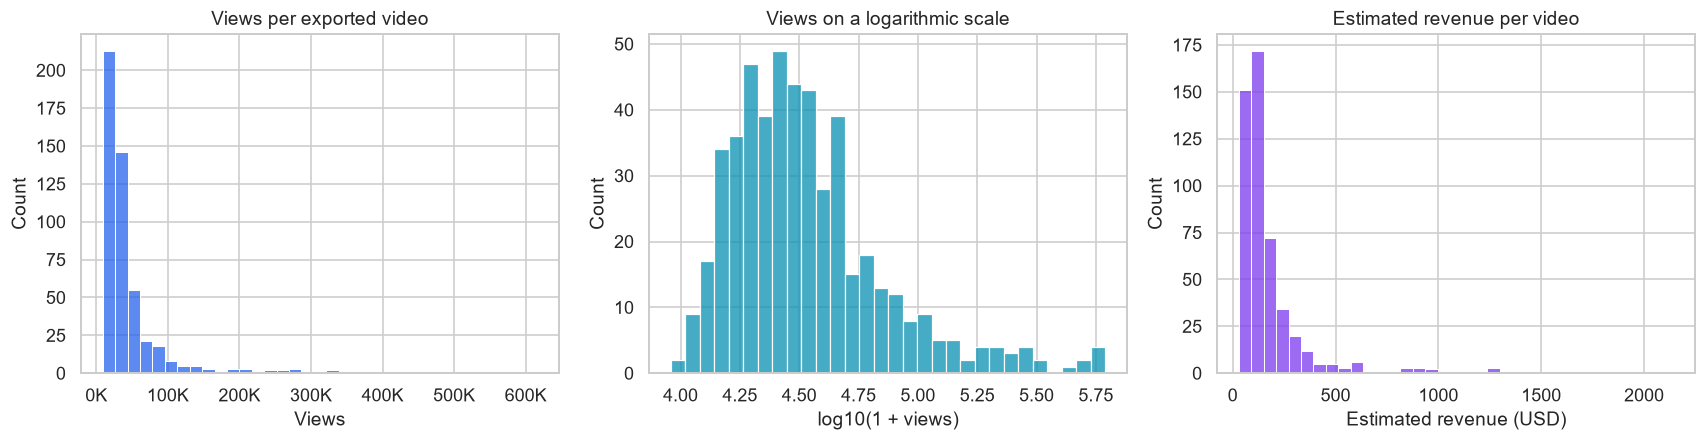

**Interpretation.** Median views are **29,144**, compared with a mean of **50,297**. The 10 most-viewed videos account for **18.5%** of subset views. This concentration is why category comparisons will show medians and sample sizes alongside totals. Extreme records remain in the main analysis unless a source error is confirmed.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(videos_clean.views, bins=35, ax=axes[0], color='#2563eb')
axes[0].set(title='Views per exported video', xlabel='Views')
sns.histplot(np.log10(1 + videos_clean.views), bins=30, ax=axes[1], color='#0891b2')
axes[1].set(title='Views on a logarithmic scale', xlabel='log10(1 + views)')
sns.histplot(videos_clean.estimated_revenue_usd, bins=35, ax=axes[2], color='#7c3aed')
axes[2].set(title='Estimated revenue per video', xlabel='Estimated revenue (USD)')
finish_plot('01_distributions')
top10_share = videos_clean.nlargest(10, 'views').views.sum() / videos_clean.views.sum() * 100
note(f"**Interpretation.** Median views are **{videos_clean.views.median():,.0f}**, compared with a mean of "
     f"**{videos_clean.views.mean():,.0f}**. The 10 most-viewed videos account for **{top10_share:.1f}%** of subset views. "
     "This concentration is why category comparisons will show medians and sample sizes alongside totals. "
     "Extreme records remain in the main analysis unless a source error is confirmed.")

## 7. Viewing duration, reach and monetization
Each dot is one exported video. A symlog views axis displays the long tail while retaining zero values. These plots describe associations, not the effect of changing a thumbnail or extending a video.

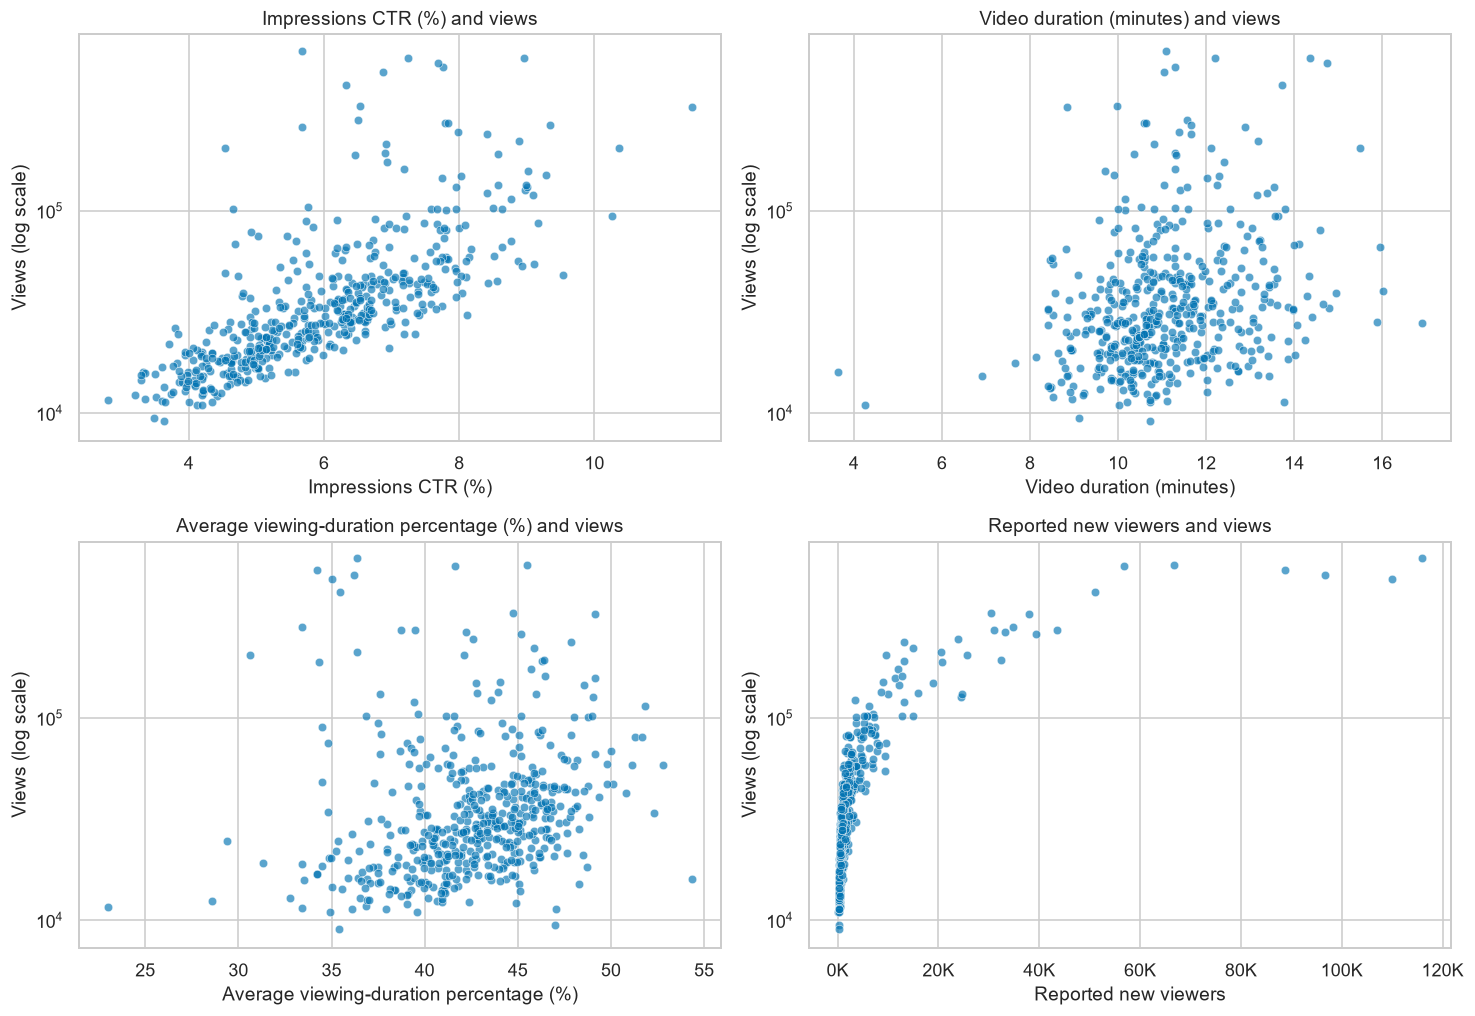

,x,y,n,pearson,spearman
0,impressions_ctr_percent,views,498,0.430,0.811
1,video_duration_minutes,views,498,0.184,0.300
2,average_view_duration_percent,views,498,-0.027,0.343
3,new_viewers,views,498,0.936,0.908
4,impressions,views,498,0.971,0.969
5,video_duration_seconds,average_view_duration_seconds,498,0.810,0.786
6,video_duration_seconds,average_view_duration_percent,498,-0.069,-0.028
7,views,estimated_revenue_usd,498,0.961,0.945


**impressions_ctr_percent vs. views:** Pearson **0.430**, Spearman **0.811** (n=498).

**video_duration_minutes vs. views:** Pearson **0.184**, Spearman **0.300** (n=498).

**average_view_duration_percent vs. views:** Pearson **-0.027**, Spearman **0.343** (n=498).

**new_viewers vs. views:** Pearson **0.936**, Spearman **0.908** (n=498).

**How to read this.** Pearson describes linear association and is sensitive to extreme values. Spearman compares ranks. Neither coefficient is a percentage of improvement or a causal estimate. New-viewer counts and views are both volume-related, so a strong relationship does not establish a content mechanism. CTR relates to eligible impressions; total views may have other sources. These are exploratory comparisons without significance claims or adjustment for publication age and topic.

In [9]:
relationships = [
    ('impressions_ctr_percent', 'Impressions CTR (%)'),
    ('video_duration_minutes', 'Video duration (minutes)'),
    ('average_view_duration_percent', 'Average viewing-duration percentage (%)'),
    ('new_viewers', 'Reported new viewers')
]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, label) in zip(axes.flat, relationships):
    sns.scatterplot(data=videos_clean, x=col, y='views', ax=ax, alpha=.65, s=28)
    ax.set(
    xlabel=label,
    ylabel='Views (log scale)',
    title=f'{label} and views'
    )
    ax.set_yscale('log')
    ax.set_ylim(
        videos_clean['views'].min() * 0.8,
        videos_clean['views'].max() * 1.2
    )
finish_plot('02_relationships_with_views')

pairs = [(c, 'views') for c, _ in relationships] + [
    ('impressions', 'views'),
    ('video_duration_seconds', 'average_view_duration_seconds'),
    ('video_duration_seconds', 'average_view_duration_percent'),
    ('views', 'estimated_revenue_usd')
]
correlation_rows = []
for x, y in pairs:
    valid = videos_clean[[x, y]].dropna()
    correlation_rows.append({'x': x, 'y': y, 'n': len(valid),
        'pearson': valid[x].corr(valid[y], method='pearson'),
        'spearman': valid[x].corr(valid[y], method='spearman')})
correlations = pd.DataFrame(correlation_rows)
display(correlations.round(3))
for row in correlations.iloc[:4].itertuples():
    note(f"**{row.x} vs. views:** Pearson **{row.pearson:.3f}**, Spearman **{row.spearman:.3f}** (n={row.n}).")
note("**How to read this.** Pearson describes linear association and is sensitive to extreme values. Spearman compares ranks. "
     "Neither coefficient is a percentage of improvement or a causal estimate. New-viewer counts and views are both volume-related, "
     "so a strong relationship does not establish a content mechanism. CTR relates to eligible impressions; total views may have other sources. "
     "These are exploratory comparisons without significance claims or adjustment for publication age and topic.")

In [10]:
ctr_row = correlations.loc[correlations.x.eq('impressions_ctr_percent')].iloc[0]
viewing_row = correlations.loc[correlations.x.eq('average_view_duration_percent')].iloc[0]
note(f"**Specific findings.** CTR has Pearson {ctr_row.pearson:.3f} and Spearman {ctr_row.spearman:.3f}. "
     "The stronger rank relationship means videos with higher CTR tend to rank higher in views, while the raw values follow a less consistent straight-line relationship. "
     f"Relative viewing duration has Pearson {viewing_row.pearson:.3f} and Spearman {viewing_row.spearman:.3f}; "
     "the difference shows why neither one coefficient nor one visual summary should stand alone. "
     "Inspect the sensitivity results next before drawing a practical conclusion.")

**Specific findings.** CTR has Pearson 0.430 and Spearman 0.811. The stronger rank relationship means videos with higher CTR tend to rank higher in views, while the raw values follow a less consistent straight-line relationship. Relative viewing duration has Pearson -0.027 and Spearman 0.343; the difference shows why neither one coefficient nor one visual summary should stand alone. Inspect the sensitivity results next before drawing a practical conclusion.

## 8. Sensitivity to the most-viewed videos
We repeat selected correlations after excluding the largest one and the largest five videos by views. This tests dependence on extreme records; it is not a reason to discard those records. The full dataset remains the primary result.

In [11]:
sensitivity_rows = []
ordered = videos_clean.sort_values(['views','video_id'], ascending=[False,True])
for remove_n in [0, 1, 5]:
    subset = ordered.iloc[remove_n:]
    for x, _ in relationships:
        valid = subset[[x,'views']].dropna()
        sensitivity_rows.append({'excluded_top_n': remove_n, 'metric': x, 'n': len(valid),
            'pearson': valid[x].corr(valid.views), 'spearman': valid[x].corr(valid.views, method='spearman')})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(3))
spans = sensitivity.groupby('metric')[['pearson','spearman']].agg(lambda s: s.max()-s.min())
display(spans.rename(columns=lambda c: c+'_range').round(3))
note('**Interpretation.** Larger coefficient ranges indicate stronger dependence on the top-viewed records. '
     'Small ranges support stability only for these exclusions; they do not rule out confounding, selection bias or other influential observations.')

,excluded_top_n,metric,n,pearson,spearman
0,0,impressions_ctr_percent,498,0.430,0.811
1,0,video_duration_minutes,498,0.184,0.300
2,0,average_view_duration_percent,498,-0.027,0.343
3,0,new_viewers,498,0.936,0.908
4,1,impressions_ctr_percent,497,0.462,0.814
5,1,video_duration_minutes,497,0.196,0.300
6,1,average_view_duration_percent,497,-0.004,0.350
7,1,new_viewers,497,0.931,0.907
8,5,impressions_ctr_percent,493,0.506,0.811
9,5,video_duration_minutes,493,0.154,0.289


,pearson_range,spearman_range
metric,,
average_view_duration_percent,0.080,0.023
impressions_ctr_percent,0.076,0.003
new_viewers,0.033,0.003
video_duration_minutes,0.042,0.011


**Interpretation.** Larger coefficient ranges indicate stronger dependence on the top-viewed records. Small ranges support stability only for these exclusions; they do not rule out confounding, selection bias or other influential observations.

## 9. Duration trade-offs and the revenue ratio
The duration percentage contains video length in its denominator. Its relationship with length can therefore have a mathematical component. Inspect absolute average seconds alongside the percentage.

Revenue per 1,000 views and absolute revenue answer different questions. We report both the median video ratio and the ratio of aggregate revenue to aggregate views; the latter weights videos by their views.

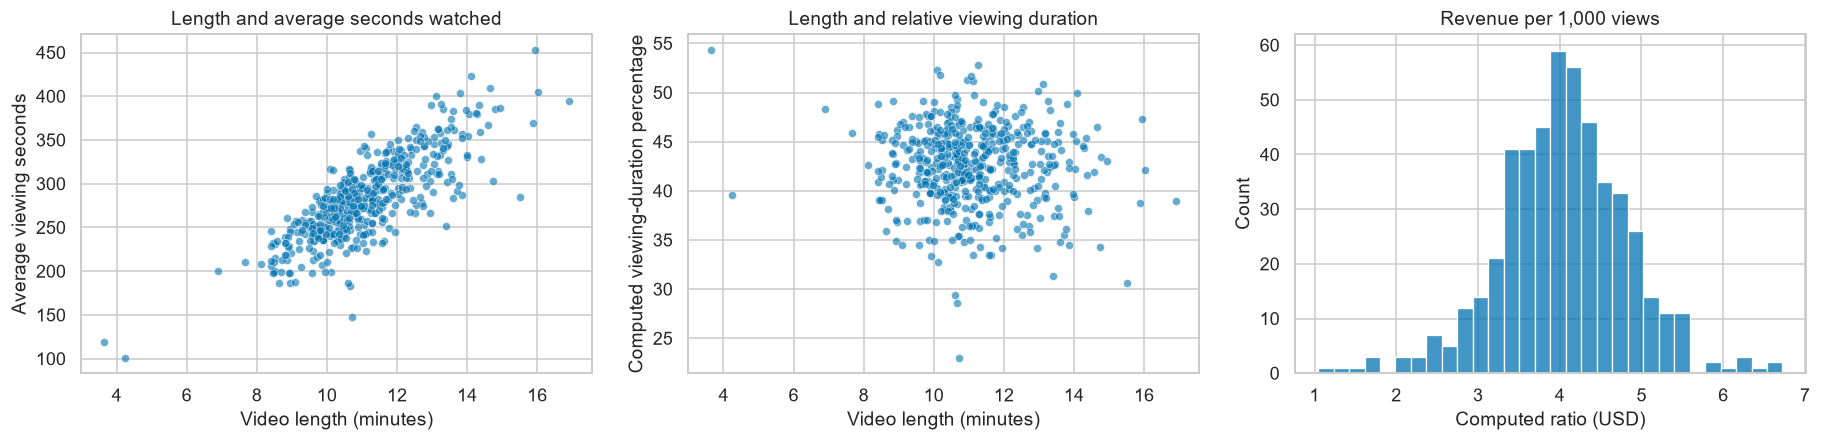

**Interpretation.** Median video length is **10.88 minutes**; median average viewing duration is **279 seconds**, and median computed viewing-duration percentage is **42.8%**. The aggregate revenue ratio is **USD 3.66 per 1,000 views**, versus a median individual-video ratio of **USD 4.04**. These separate medians need not algebraically reconcile. None of these measures establishes profit or an optimal causal video length.

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=videos_clean, x='video_duration_minutes', y='average_view_duration_seconds', ax=axes[0], alpha=.6, s=25)
axes[0].set(title='Length and average seconds watched', xlabel='Video length (minutes)', ylabel='Average viewing seconds')
sns.scatterplot(data=videos_clean, x='video_duration_minutes', y='average_view_duration_percent', ax=axes[1], alpha=.6, s=25)
axes[1].set(title='Length and relative viewing duration', xlabel='Video length (minutes)', ylabel='Computed viewing-duration percentage')
sns.histplot(videos_clean.estimated_revenue_per_1000_views_usd, bins=30, ax=axes[2])
axes[2].set(title='Revenue per 1,000 views', xlabel='Computed ratio (USD)')
finish_plot('03_duration_and_monetization')
aggregate_ratio = videos_clean.estimated_revenue_usd.sum() / videos_clean.views.sum() * 1000
note(f"**Interpretation.** Median video length is **{videos_clean.video_duration_minutes.median():.2f} minutes**; "
     f"median average viewing duration is **{videos_clean.average_view_duration_seconds.median():.0f} seconds**, "
     f"and median computed viewing-duration percentage is **{videos_clean.average_view_duration_percent.median():.1f}%**. "
     f"The aggregate revenue ratio is **USD {aggregate_ratio:.2f} per 1,000 views**, versus a median individual-video ratio of "
     f"**USD {videos_clean.estimated_revenue_per_1000_views_usd.median():.2f}**. "
     "These separate medians need not algebraically reconcile. None of these measures establishes profit or an optimal causal video length.")

## Video-level examples for qualitative follow-up
The top-viewed and highest-ratio lists are different rankings. The revenue-ratio shortlist below requires at least the dataset's median views, a transparent descriptive screen to avoid highlighting tiny denominators. It is not a statistical cutoff or a final recommendation. Review actual content before explaining why a video performed well.

In [13]:
example_columns = ['video_id','video_title','publish_date','views','estimated_revenue_usd','impressions_ctr_percent','average_view_duration_percent','estimated_revenue_per_1000_views_usd']
note('**Ten most-viewed exported videos**')
display(videos_clean.nlargest(10, 'views')[example_columns].round(3))
note('**Highest computed revenue ratios among videos at or above median views**')
display(videos_clean.loc[videos_clean.views.ge(videos_clean.views.median())].nlargest(10, 'estimated_revenue_per_1000_views_usd')[example_columns].round(3))

**Ten most-viewed exported videos**

C:\Users\USUARIO1\AppData\Local\Temp\ipykernel_18244\2976741650.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(videos_clean.nlargest(10, 'views')[example_columns].round(3))


,video_id,video_title,publish_date,views,estimated_revenue_usd,impressions_ctr_percent,average_view_duration_percent,estimated_revenue_per_1000_views_usd
308,Ja_Z8TB9qio,4 MEJORES TES PARA DORMIR RAPIDO Y ELIMINAR EL INSOMNIO,2025-06-11,616088,2142.443,5.67,36.391,3.477
422,c6Q0mnB7364,JUGO DE SABILA EN AYUNAS 5 NUEVOS BENEFICIOS DESCUBIERTOS DEL...,2025-02-11,566561,1395.394,8.96,45.492,2.463
427,Fe-JJPqH1K0,SEMILLA DE AGUACATE MOLIDA TODOS LOS DIAS - RECETA SECRETA RE...,2025-02-06,563104,1920.213,7.24,41.647,3.410
321,WCjx_DpM7pA,1 CUCHARADA DE ACEITE DE OLIVA CON LIMON EN AYUNAS TODOS LOS ...,2025-05-29,536992,1699.627,7.68,34.237,3.165
266,PDHvDuJaevM,"AGUA CON BICARBONATO EN AYUNAS - Beneficios, Para Que Sirve Y...",2025-07-23,508434,1280.787,7.76,36.189,2.519
400,oi8ZRpcXtHM,Agua De Avena En Ayunas Por 1 Semana - Para Qué Sirve? - Bene...,2025-03-07,483041,1280.744,6.88,35.045,2.651
101,AILe7BdL9Q8,1 CUCHARADA DE ACEITE DE OLIVA CON LIMON EN AYUNAS - Para Que...,2026-01-29,415994,1240.615,6.33,35.480,2.982
177,xxsRDF-3gCA,TE DE ROMERO EN AYUNAS - Para Que Sirve? - Beneficios Para Tu...,2025-11-10,328694,924.714,6.53,44.741,2.813
458,ljr9dpCcK4Q,LA PRÓXIMA EPIDEMIA! - HMPV EL NUEVO VIRUS CHINO DEL 2025,2025-01-06,324970,424.265,11.44,49.153,1.306
347,oswjabhCopQ,CAFE CON CANELA EN AYUNAS - Beneficios Y Contraindicaciones P...,2025-05-01,279190,947.251,6.50,33.429,3.393


**Highest computed revenue ratios among videos at or above median views**

C:\Users\USUARIO1\AppData\Local\Temp\ipykernel_18244\2976741650.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(videos_clean.loc[videos_clean.views.ge(videos_clean.views.median())].nlargest(10, 'estimated_revenue_per_1000_views_usd')[example_columns].round(3))


,video_id,video_title,publish_date,views,estimated_revenue_usd,impressions_ctr_percent,average_view_duration_percent,estimated_revenue_per_1000_views_usd
482,cswITHbggmk,Café Con Miel En Ayunas ¿Para Qué Sirve? - Beneficios Para Tu...,2024-12-13,159705,930.983,7.19,46.460,5.829
160,NqYvkO8qP8s,"TE DE CLAVO DE OLOR EN AYUNAS - Para Que Sirve, Beneficios Y ...",2025-11-27,33793,187.362,6.45,52.310,5.544
317,kOHHyNn_euM,JUGO DE MANZANA VERDE CON ESPINACA - ¿Para Qué Sirve?,2025-06-02,50358,278.767,7.95,45.202,5.536
262,DeJcWpNmBNk,AGUA DE PEPINO CON CHÍA - ¿Para Qué Sirve? - Beneficios Para ...,2025-07-27,35236,194.800,5.34,42.751,5.528
332,f_L_Uij4pFw,COMO SER MAS INTELIGENTE Y AGRANDAR TU CEREBRO,2025-05-16,51512,283.500,7.79,44.951,5.504
407,_AEp_5tx2Z8,5 PASOS PARA BAJAR DE PESO FACIL EN 2 SEMANAS,2025-02-26,33270,182.943,7.07,43.593,5.499
54,uoMwBO1dtB4,NO TOMES CAFÉ - Contraindicaciones De Tomar Cafe Que Debes Co...,2026-03-17,35880,197.228,6.20,45.739,5.497
489,FOVfgRQ321E,COMO DORMIR BIEN COMO UN BEBE 2025 - Elimina El Insomnio Y La...,2024-12-06,44867,245.081,6.73,46.961,5.462
176,zxoJoBG4jwQ,NO TOMES CAFE! - Contraindicaciones Y Enfermedades Por Consum...,2025-11-11,31057,167.576,6.58,43.411,5.396
344,DrcEJ0Hni0I,COMO BAJAR EL AZUCAR PARA SIEMPRE - Técnicas Y Alimentos Para...,2025-05-04,39143,207.349,6.50,43.032,5.297


## 10. Publication cohorts
These charts group the exported videos by publication month. They show publication volume and median accumulated/export-window views for each cohort. They do **not** show how many views the channel received each month.

The last cohort may be incomplete. We do not divide by days since publication because the exact metric window and extraction cutoff have not been confirmed; daily averages would also assume a rate pattern that may be unrealistic.

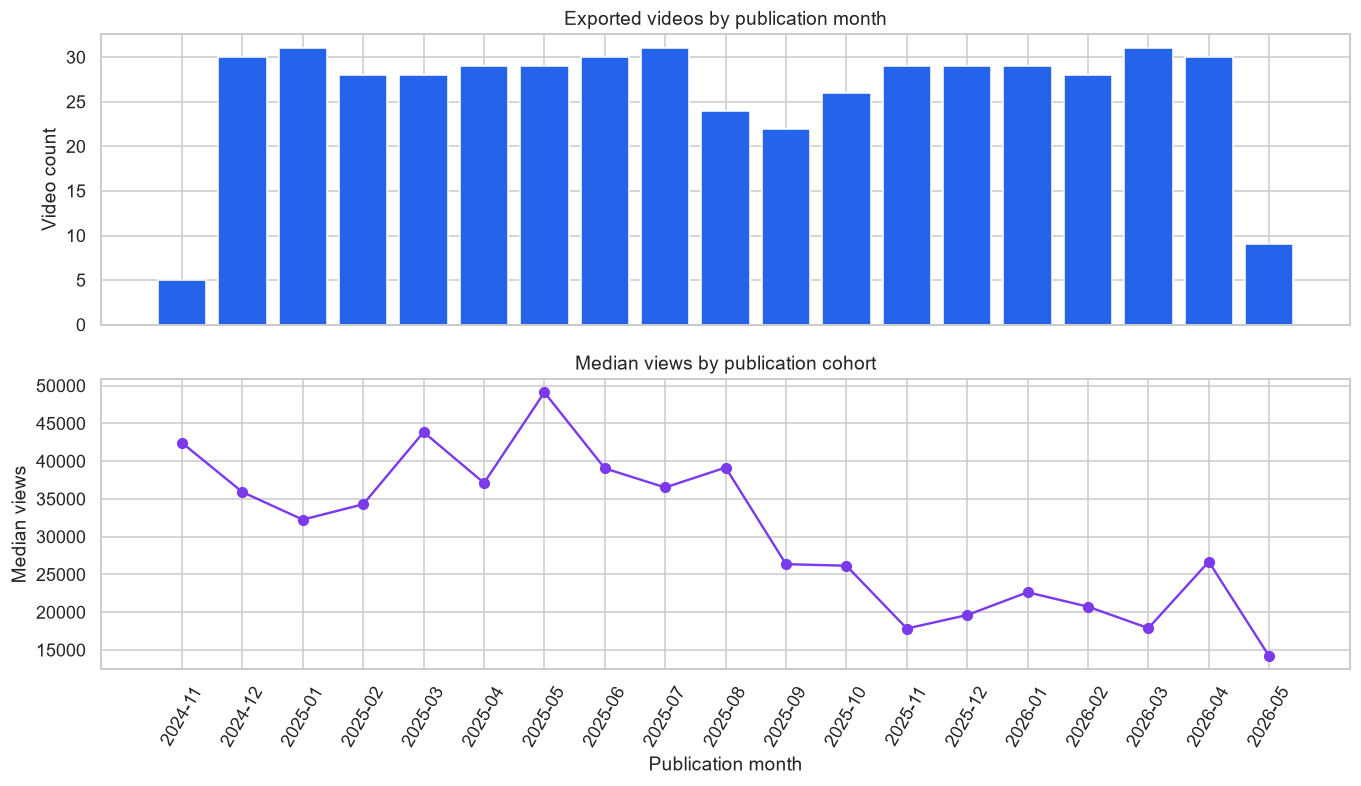

,publish_month,video_count,median_views
0,2024-11,5,42433.0
1,2024-12,30,35913.5
2,2025-01,31,32265.0
3,2025-02,28,34301.0
4,2025-03,28,43853.0
5,2025-04,29,37123.0
6,2025-05,29,49116.0
7,2025-06,30,39054.0
8,2025-07,31,36522.0
9,2025-08,24,39163.5


**Interpretation.** The highest observed cohort median is **2025-05**, with **49,116 views** across **29 videos**. This is descriptive: differences can reflect exposure time, content mix, selection and distribution conditions, not a change in channel performance alone.

In [14]:
cohorts = videos_clean.groupby('publish_month').agg(video_count=('video_id','size'), median_views=('views','median')).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].bar(cohorts.publish_month, cohorts.video_count, color='#2563eb')
axes[0].set(title='Exported videos by publication month', ylabel='Video count')
axes[1].plot(cohorts.publish_month, cohorts.median_views, marker='o', color='#7c3aed')
axes[1].set(title='Median views by publication cohort', ylabel='Median views', xlabel='Publication month')
axes[1].tick_params(axis='x', rotation=60)
finish_plot('04_publication_cohorts')
display(cohorts)
best_cohort = cohorts.loc[cohorts.median_views.idxmax()]
note(f"**Interpretation.** The highest observed cohort median is **{best_cohort['publish_month']}**, "
     f"with **{best_cohort.median_views:,.0f} views** across **{int(best_cohort.video_count)} videos**. "
     "This is descriptive: differences can reflect exposure time, content mix, selection and distribution conditions, not a change in channel performance alone.")

# C — Construct
## 11. Construct a transparent content taxonomy
This phase constructs reusable analytical features, summaries and review files. It does **not** fit a predictive model: a defensible prediction target and common observation window are not established.

### Category rules
1. Normalize accents, spacing and case, retaining original titles.
2. Identify explicit health-topic keywords. A single detected topic takes priority over ingredients.
3. If several health topics are detected, leave the primary category unresolved for manual review.
4. If no specific health topic is detected but an ingredient, food or supplement is explicit, propose `Food, Herbs & Supplements`.
5. Otherwise leave the video `Unclassified`.

This deliberately broad food category can dominate the dataset and conceal subtopics. It is a starting taxonomy, not a proven optimal segmentation. Proposed assignments are not verified by watching the videos. Generic phrases such as “health and beauty” do not establish a skin-health topic.

**Review contract:** `proposed_category` preserves the automated suggestion; `final_category` is a human override; `review_status` records approval. A proposal may be approved unchanged. Set status to `Reviewed` only after verification. Topic and live/uploaded format are separate fields.

## Content Category Classification

The source export does not include content categories. We will prepare
a title inventory and document proposed categories in a separate CSV file.

Categories will be defined after reviewing the full title inventory.
Ambiguous titles will remain pending until additional content information
is available.

Proposed labels and reviewed decisions will be tracked separately.
Category comparisons will be updated after the classification review.

In [15]:
# Export all video titles for category review.
category_review = videos_clean[
    ["video_id", "video_title", "video_url"]
].copy()

titles_path = processed_dir / "long_form_titles_for_review.csv"

category_review.to_csv(
    titles_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"Videos exported: {len(category_review)}")
print(f"Saved to: {titles_path}")

display(category_review.head())

Videos exported: 498
Saved to: C:\Users\USUARIO1\Documents\youtube-long-form-performance-analysis\data\processed\long_form_titles_for_review.csv


,video_id,video_title,video_url
1,gQXwLdGldFY,"JUGO DE REPOLLO MORADO EN AYUNAS - Para Que Sirve, Beneficios...",https://www.youtube.com/watch?v=gQXwLdGldFY
2,1L-yEOCMv3I,"TE DE JENGIBRE CON LIMON TODOS LOS DIAS - Para Que Sirve, Ben...",https://www.youtube.com/watch?v=1L-yEOCMv3I
3,zqZ3xqS1v08,PODEROSO JUGO DE BETABEL EN AYUNAS - ¿Para Qué Sirve La Remol...,https://www.youtube.com/watch?v=zqZ3xqS1v08
4,gVxROQYr1uA,"TE DE CEBOLLA ROJA TODOS LOS DIAS - Para Que Sirve, Beneficio...",https://www.youtube.com/watch?v=gVxROQYr1uA
5,noj0r31-vqQ,"TE DE CANELA Y CLAVO DE OLOR TODOS LOS DIAS - Para Que Sirve,...",https://www.youtube.com/watch?v=noj0r31-vqQ


In [16]:
# Load the new category proposals.
category_review = pd.read_csv(
    processed_dir / "long_form_categories_draft_v2.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

print(f"Videos loaded: {len(category_review)}")

display(category_review["proposed_category"].value_counts())

Videos loaded: 498


proposed_category
Teas & Infusions                          103
Juices & Smoothies                         89
Fruits & Vegetables                        46
Herbs & Spices                             33
Prepared Waters & Hydration                27
Seeds & Nuts                               26
Oils & Vinegars                            22
Vitamins, Minerals & Other Supplements     20
Digestive Health                           12
Coffee                                      9
Diabetes & Blood Sugar                      8
Oats, Grains & Legumes                      8
Soups & Broths                              8
Kidney & Urinary Health                     7
Plant-Based Milks                           6
Aloe Vera Preparations                      5
Liver & Gallbladder Health                  5
Skin Care                                   4
Cancer                                      4
Cocoa & Chocolate                           4
Unclassified                                4
Eye Health      

### Review ambiguous category proposals

We prioritize titles with unclear subjects, multiple topics, or ambiguous
preparations. Video links and classification notes support this review.

All labels remain proposals until confirmed. “Needs review” identifies
priority cases; it does not mean that other proposals are already verified.

In [17]:
needs_review = category_review.loc[
    category_review["review_status"] == "Needs review"
].copy()

print(f"Videos needing review: {len(needs_review)}")

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None
):
    display(
        needs_review[
            [
                "video_title",
                "video_url",
                "proposed_category",
                "classification_note"
            ]
        ]
    )

Videos needing review: 24


,video_title,video_url,proposed_category,classification_note
27,"COMO DESHINCHAR DE TANTO COMER - Elimina La Hinchazón de Panza, Retención Y Baja de Peso",https://www.youtube.com/watch?v=bZ7sqPUrGec,Digestive Health,Title-based proposal: main subject is Digestive Health. No video or transcript checked. Multiple health references occur; confirm the proposed main focus.
74,"JUEGO DE CIRUELAS PASAS CON LINAZA - PARA QUE SIRVE, BENEFICIOS Y CONTRAINDICACIONES PARA TU SALUD",https://www.youtube.com/watch?v=UZ7K62EfUjI,Juices & Smoothies,Probable title typo: JUEGO DE CIRUELAS interpreted as JUGO; confirm preparation. No video checked.
76,7 DIAS USANDO AGUA DE ARROZ - Para Que Sirve Y Beneficios Para Tu Salud,https://www.youtube.com/watch?v=ND7QFbsZsxg,Prepared Waters & Hydration,"Title-based proposal: main subject is Prepared Waters & Hydration. No video or transcript checked. Preparation, route of use or main focus needs confirmation from content."
98,"ASTRÁGALUS CURA TODO! - LA MEJOR HIERBA PARA TUS RIÑONES, CORAZÓN Y DEFENSAS.",https://www.youtube.com/watch?v=ievzXrjDyt8,Herbs & Spices,Title-based proposal: main subject is Herbs & Spices. No video or transcript checked. Multiple health references occur; confirm the proposed main focus.
140,LA MEZCLA PARA NUNCA ENFERMARTE - Formula Secreta Del Dr. Landivar,https://www.youtube.com/watch?v=7_D13cst1Nw,Unclassified,Title describes an unspecified mixture or blood-cleansing claim; inspect content to identify the main subject. Do not infer a diagnosis.
142,"CURSO DESTRUCTOR DE AZÚCAR CONTRA LA DIABETES, RESISTENCIA A LA INSULINA Y MALA CIRCULACIÓN",https://www.youtube.com/watch?v=eP3gRaxYC5k,Diabetes & Blood Sugar,Title-based proposal: main subject is Diabetes & Blood Sugar. No video or transcript checked. Multiple health references occur; confirm the proposed main focus.
184,AGUA DE ARROZ PARA TODO! - ¿Para Qué Sirve El Agua De Arroz? - Beneficios Para Tu Salud Y Belleza,https://www.youtube.com/watch?v=mAjQCqCS97I,Prepared Waters & Hydration,"Title-based proposal: main subject is Prepared Waters & Hydration. No video or transcript checked. Preparation, route of use or main focus needs confirmation from content."
219,"CASCARA DE NARANJA CON CLAVO DE OLOR - Para Que Sirve, Beneficios Y Contraindicaciones Para Tu Salud",https://www.youtube.com/watch?v=7nisQMSyIBs,Herbs & Spices,"Title-based proposal: main subject is Herbs & Spices. No video or transcript checked. Preparation, route of use or main focus needs confirmation from content."
222,"AGUACATE CON ACEITE DE OLIVA TODOS LOS DÍAS - Para Que Sirve, Beneficios Y Contraindicaciones",https://www.youtube.com/watch?v=QJ4ex5A8_uU,Oils & Vinegars,"Title-based proposal: main subject is Oils & Vinegars. No video or transcript checked. Preparation, route of use or main focus needs confirmation from content."
246,"PAPAYA CON LINAZA EN AYUNAS - Como Hacerlo, Beneficios Y Contraindicaciones",https://www.youtube.com/watch?v=l72vh8fpEUU,Fruits & Vegetables,"Title-based proposal: main subject is Fruits & Vegetables. No video or transcript checked. Preparation, route of use or main focus needs confirmation from content."


In [18]:
# Show only videos without a proposed category.
unclassified_videos = category_review.loc[
    category_review["proposed_category"] == "Unclassified"
].copy()

print(f"Unclassified videos: {len(unclassified_videos)}")

with pd.option_context("display.max_colwidth", None):
    display(
        unclassified_videos[
            ["video_title", "video_url"]
        ]
    )

Unclassified videos: 4


,video_title,video_url
140,LA MEZCLA PARA NUNCA ENFERMARTE - Formula Secreta Del Dr. Landivar,https://www.youtube.com/watch?v=7_D13cst1Nw
295,LIMPIA TU SANGRE CON ESTA MEZCLA Y REGENERA TU CUERPO,https://www.youtube.com/watch?v=XNKUGuRo6L0
342,"LIMPIA TU SANGRE CON ESTE JUGO - Desintoxica, Mejora Tu Anemia Y Mas",https://www.youtube.com/watch?v=Qw_Kj9VU28c
405,EL MEJOR JUGO PARA LIMPIAR LA SANGRE - Como Hacerlo y Contraindicaciones,https://www.youtube.com/watch?v=u1XcYzYXJ7c


### Category assignments based on supplied summaries

Four previously unclassified videos were assigned categories using
user-supplied Gemini summaries. These assignments have not been independently
verified against the videos or transcripts.

Categories describe content, not the medical validity of its claims.
The fourth assignment remains provisional because its summary describes
multiple dietary approaches despite the title referring to a juice.

In [19]:
# Assign categories using the supplied summaries.
category_updates = {
    "7_D13cst1Nw": "Immune Health",
    "XNKUGuRo6L0": "Juices & Smoothies",
    "Qw_Kj9VU28c": "Juices & Smoothies",
    "u1XcYzYXJ7c": "Nutrition Advice & Food Lists",
}

assert category_review["video_id"].is_unique
assert set(category_updates).issubset(set(category_review["video_id"]))

for video_id, category in category_updates.items():
    mask = category_review["video_id"] == video_id

    category_review.loc[mask, "final_category"] = category
    category_review.loc[mask, "review_status"] = "Assigned from supplied summary"
    category_review.loc[mask, "classification_note"] = (
        "Assigned from a user-supplied Gemini summary; "
        "video/transcript not independently verified."
    )

category_review.loc[
    category_review["video_id"] == "u1XcYzYXJ7c",
    "classification_note"
] += " Provisional: summary describes multiple dietary approaches, unlike the juice-focused title."

display(
    category_review.loc[
        category_review["video_id"].isin(category_updates),
        ["video_title", "final_category", "review_status"]
    ]
)

,video_title,final_category,review_status
140,LA MEZCLA PARA NUNCA ENFERMARTE - Formula Secreta Del Dr. Lan...,Immune Health,Assigned from supplied summary
295,LIMPIA TU SANGRE CON ESTA MEZCLA Y REGENERA TU CUERPO,Juices & Smoothies,Assigned from supplied summary
342,"LIMPIA TU SANGRE CON ESTE JUGO - Desintoxica, Mejora Tu Anemi...",Juices & Smoothies,Assigned from supplied summary
405,EL MEJOR JUGO PARA LIMPIAR LA SANGRE - Como Hacerlo y Contrai...,Nutrition Advice & Food Lists,Assigned from supplied summary


In [21]:
has_final_category = (
    category_review["final_category"]
    .fillna("")
    .str.strip()
    .ne("")
)

print("With final category:", has_final_category.sum())
print("Without final category:", (~has_final_category).sum())

With final category: 4
Without final category: 494


In [20]:
# Identify videos without a final category.
missing_final = (
    category_review["final_category"]
    .fillna("")
    .str.strip()
    .eq("")
)

# Confirm that every remaining proposal has a category.
assert category_review.loc[
    missing_final, "proposed_category"
].fillna("").str.strip().isin(["", "Unclassified"]).sum() == 0

# Accept the remaining title-based proposals.
category_review.loc[missing_final, "final_category"] = (
    category_review.loc[missing_final, "proposed_category"]
)

category_review.loc[missing_final, "review_status"] = (
    "Accepted from title"
)

print(f"Categories accepted: {missing_final.sum()}")
print(
    "Videos with final category:",
    category_review["final_category"].fillna("").str.strip().ne("").sum()
)

Categories accepted: 494
Videos with final category: 498


### Integrate the selected categories

Final working categories are matched to video metrics using video_id.
We check identifier uniqueness and coverage before assigning categories.

Classification status is preserved to distinguish title-based assignments
from assignments based on supplied summaries.

In [21]:
# Check that both tables contain the same unique video IDs.
assert videos_clean["video_id"].is_unique
assert category_review["video_id"].is_unique
assert set(videos_clean["video_id"]) == set(category_review["video_id"])

# Use video IDs to match each video with its classification.
category_lookup = category_review.set_index("video_id")

videos_clean["content_category"] = videos_clean["video_id"].map(
    category_lookup["final_category"]
)

videos_clean["review_status"] = videos_clean["video_id"].map(
    category_lookup["review_status"]
)

videos_clean["classification_note"] = videos_clean["video_id"].map(
    category_lookup["classification_note"]
)

# Confirm complete category coverage.
assert not videos_clean["content_category"].fillna("").str.strip().isin(
    ["", "Unclassified"]
).any()

print("Total videos:", len(videos_clean))
print("Videos with category:", videos_clean["content_category"].notna().sum())

display(
    videos_clean[
        ["video_title", "content_category", "review_status", "views"]
    ].head()
)

Total videos: 498
Videos with category: 498


,video_title,content_category,review_status,views
1,"JUGO DE REPOLLO MORADO EN AYUNAS - Para Que Sirve, Beneficios...",Juices & Smoothies,Accepted from title,11999
2,"TE DE JENGIBRE CON LIMON TODOS LOS DIAS - Para Que Sirve, Ben...",Teas & Infusions,Accepted from title,12520
3,PODEROSO JUGO DE BETABEL EN AYUNAS - ¿Para Qué Sirve La Remol...,Juices & Smoothies,Accepted from title,14180
4,"TE DE CEBOLLA ROJA TODOS LOS DIAS - Para Que Sirve, Beneficio...",Teas & Infusions,Accepted from title,19337
5,"TE DE CANELA Y CLAVO DE OLOR TODOS LOS DIAS - Para Que Sirve,...",Teas & Infusions,Accepted from title,21404


### Performance by content category

We group videos by their selected content category to compare publishing
volume, typical views, and total contributions to views and estimated revenue.

Median views describe the typical video within each category, while totals
reflect both publishing volume and individual video performance.
Video counts are included because results based on very few videos may
not represent a consistent pattern.

Categories include title-based assignments and assignments based on
supplied summaries. These comparisons are descriptive and do not establish
that a topic causes higher performance.

In [22]:
category_summary = (
    videos_clean
    .groupby("content_category")
    .agg(
        video_count=("video_id", "size"),
        median_views=("views", "median"),
        total_views=("views", "sum"),
        total_revenue_usd=("estimated_revenue_usd", "sum")
    )
    .sort_values("median_views", ascending=False)
    .reset_index()
)

# Confirm that every video is included in the category summary.
assert category_summary["video_count"].sum() == len(videos_clean)

with pd.option_context("display.max_rows", None):
    display(category_summary.round(2))

,content_category,video_count,median_views,total_views,total_revenue_usd
0,Gelatin & Collagen,1,81575.0,81575,310.74
1,Eggs & Animal Foods,4,66244.0,280005,1034.52
2,Medications,1,47635.0,47635,184.86
3,Eye Health,4,46020.5,388082,1492.74
4,Immune Health,1,43783.0,43783,229.08
5,Pancreatic Health,2,40950.0,81900,368.87
6,Brain & Mental Health,4,40357.0,167933,786.03
7,Nutrition Advice & Food Lists,4,39860.0,156824,649.52
8,Prepared Waters & Hydration,27,37240.0,2380269,7012.95
9,Digestive Health,12,37188.5,449229,1611.39


### Typical video performance by category

This chart compares median views across categories with at least five
exported videos. Labels include the number of videos contributing to
each median.

The minimum count is a descriptive display rule, not a statistical
significance threshold. Smaller categories remain in the complete
summary table.

These comparisons do not adjust for publication age or differences in
content and audience. They describe the exported dataset rather than
the causal effect of choosing a category.

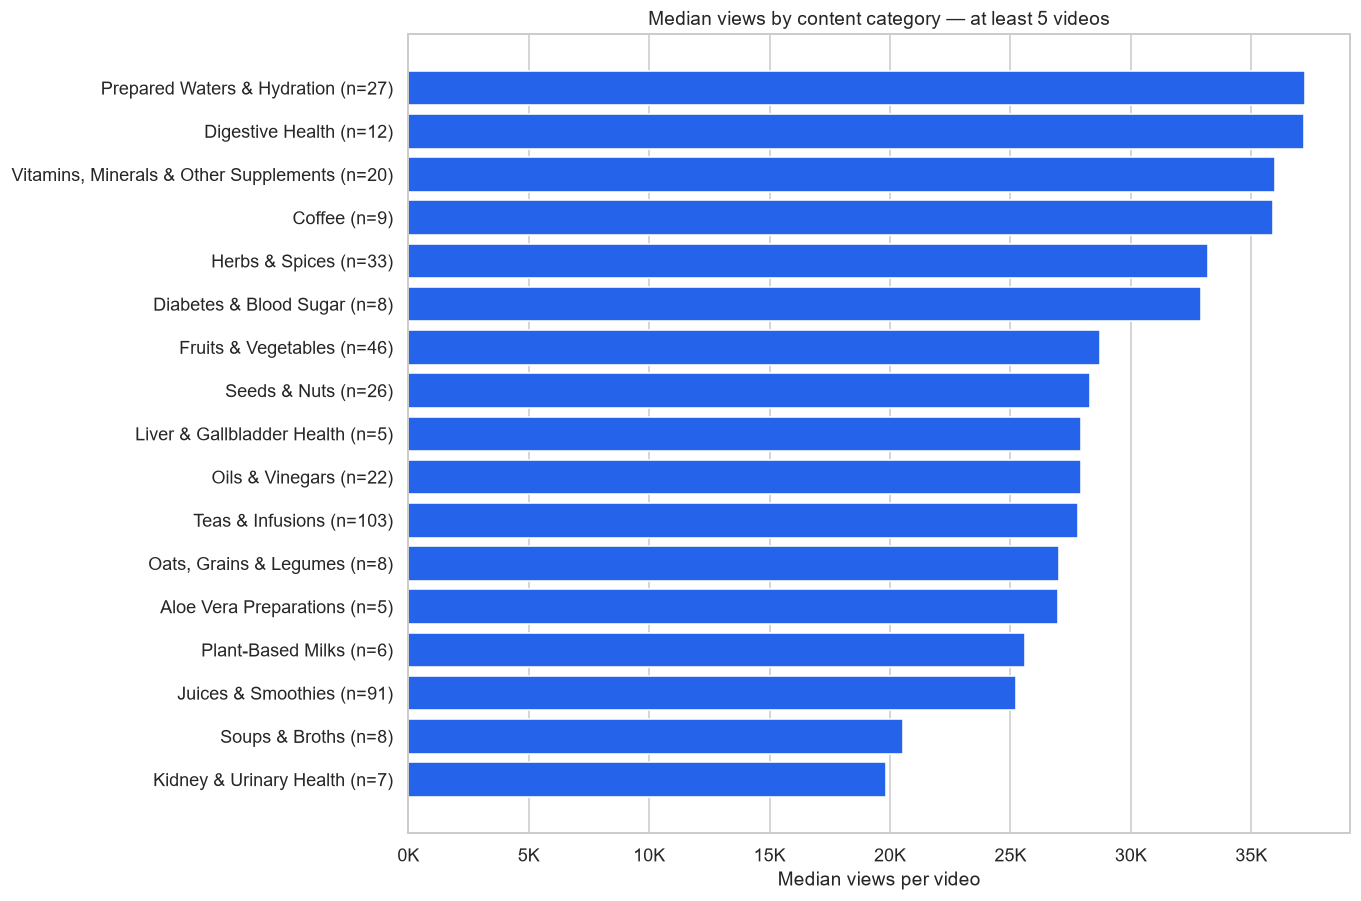

In [23]:
# Keep categories with at least five videos for this comparison.
category_plot = (
    category_summary
    .loc[category_summary["video_count"] >= 5]
    .sort_values("median_views", ascending=True)
    .copy()
)

# Include sample sizes directly in the labels.
category_plot["category_label"] = (
    category_plot["content_category"]
    + " (n="
    + category_plot["video_count"].astype(str)
    + ")"
)

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    category_plot["category_label"],
    category_plot["median_views"],
    color="#2563eb"
)

ax.set(
    title="Median views by content category — at least 5 videos",
    xlabel="Median views per video",
    ylabel=""
)

ax.grid(axis="y", visible=False)

finish_plot("05_category_median_views")

### Findings — Median views by category

Among categories with at least five videos, **Prepared Waters & Hydration**
has the highest median views (**37,240; n=27**), closely followed by
**Digestive Health** (**37,188.5; n=12**). The difference is only 51.5 views,
so these categories have effectively similar observed medians.

**Vitamins, Minerals & Other Supplements** (**35,967; n=20**) and
**Coffee** (**35,880; n=9**) also show relatively high typical views
within this comparison.

The most frequently published categories do not lead in median views.
**Teas & Infusions** has 103 videos and a median of **27,819 views**,
while **Juices & Smoothies** has 91 videos and a median of **25,236 views**.
Their substantial total reach therefore does not imply the highest
typical performance per video.

At the lower end of the displayed categories, **Kidney & Urinary Health**
has a median of **19,819 views** across seven videos, followed by
**Soups & Broths** at **20,533 views** across eight videos.

**Business implication:** Prepared Waters & Hydration and Digestive Health
are candidates for further investigation and content testing. This chart
alone does not justify reallocating production away from other categories.

**Limitations:** Medians do not show the spread of individual results.
Publication age, content differences, and classification uncertainty remain
uncontrolled. Categories with fewer than five videos are excluded from
this chart but retained in the full summary.

### Distribution of views within categories

We compare view distributions for categories with at least five videos,
using the same categories as the median-view chart.

Boxes show the middle 50% of observations, with the median marked inside.
Whiskers extend to observations within 1.5 times the interquartile range
from the box. Points beyond the whiskers remain in the analysis.

A logarithmic axis makes both typical videos and highly viewed videos
visible. Equal distances represent multiplicative changes in views,
rather than equal absolute increases.

This comparison describes variation within the exported dataset.
It does not establish future performance or control for publication age.

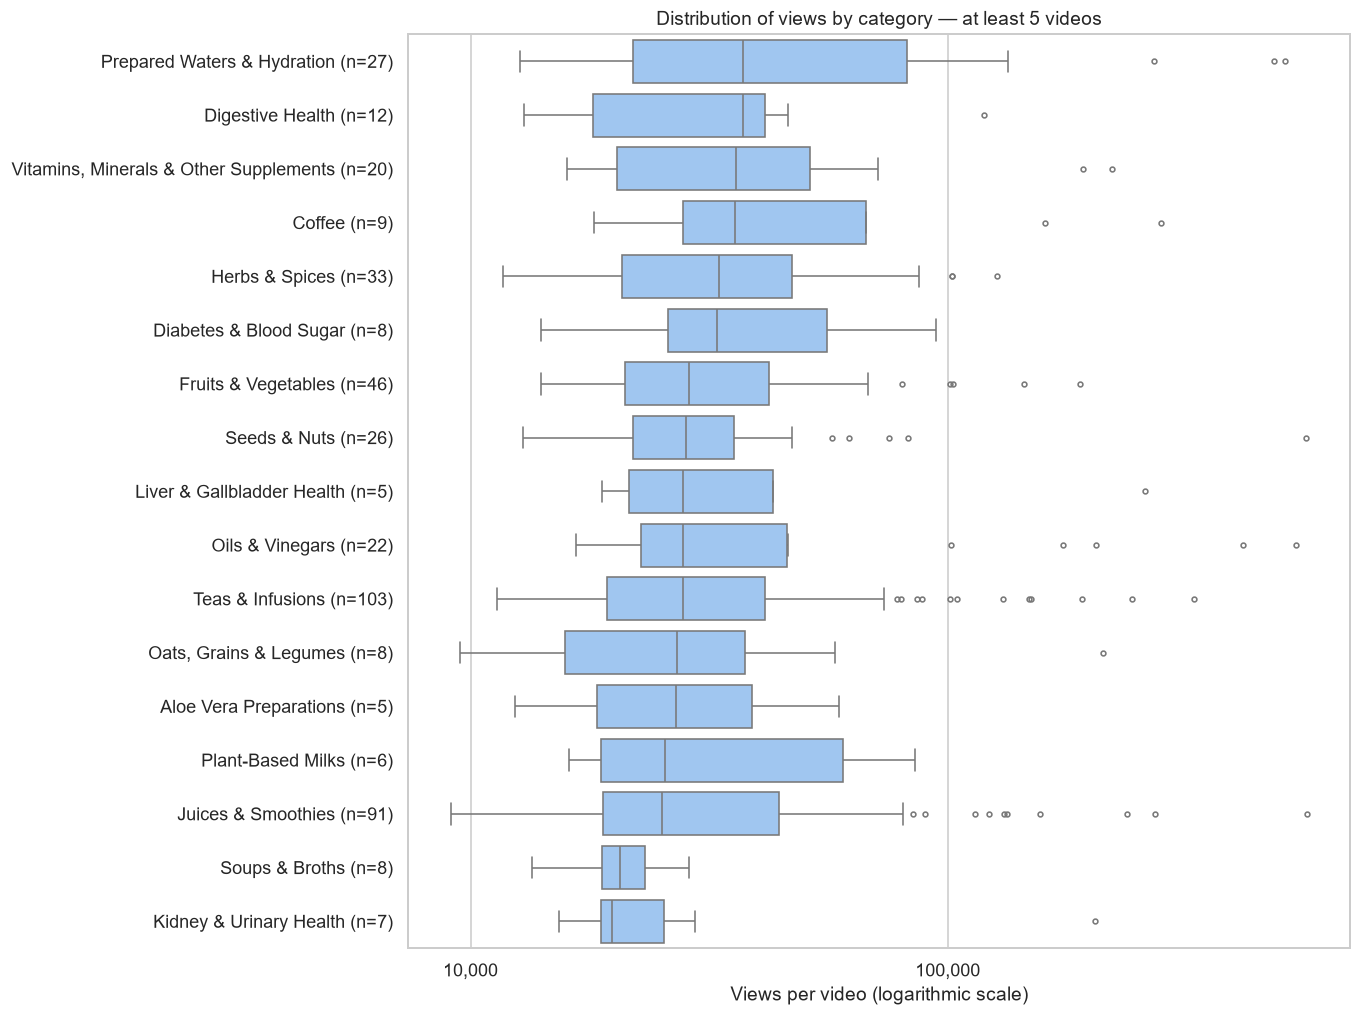

In [24]:
# Select categories and order them by median views.
selected_categories = (
    category_summary
    .loc[category_summary["video_count"] >= 5]
    .sort_values("median_views", ascending=False)
)

category_order = selected_categories["content_category"].tolist()

# Use individual videos, not the aggregated summary.
category_videos = videos_clean.loc[
    videos_clean["content_category"].isin(category_order)
].copy()

# A logarithmic axis requires positive values.
assert category_videos["views"].notna().all()
assert category_videos["views"].gt(0).all()

fig, ax = plt.subplots(figsize=(12, 9))

sns.boxplot(
    data=category_videos,
    x="views",
    y="content_category",
    order=category_order,
    color="#93c5fd",
    showfliers=True,
    fliersize=3,
    ax=ax
)

ax.set_xscale("log")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:,.0f}")
)

ax.set_yticks(
    range(len(category_order)),
    labels=[
        f"{row.content_category} (n={row.video_count})"
        for row in selected_categories.itertuples()
    ]
)

ax.set(
    title="Distribution of views by category — at least 5 videos",
    xlabel="Views per video (logarithmic scale)",
    ylabel=""
)

ax.grid(axis="y", visible=False)

finish_plot("06_category_view_distributions")

### Findings — Within-category variation in views

**Similar medians can conceal different distributions.**
Prepared Waters & Hydration and Digestive Health have nearly identical
median views, but Prepared Waters & Hydration shows a wider middle
50% on the logarithmic axis. Its central results are more dispersed
in relative terms.

**High-volume categories include standout videos.**
Teas & Infusions and Juices & Smoothies contain multiple observations
well above their central distributions. These standout videos help
explain why substantial total reach can coexist with moderate
median views.

**Concentrated performance is not necessarily high performance.**
Soups & Broths shows a relatively compact distribution around a
lower median. Kidney & Urinary Health also has a compact central
distribution, alongside a notably higher-viewed observation.

**Business implication:** Review standout videos individually to
identify candidate patterns in subject, title, duration, and
publication timing. Treat these patterns as hypotheses for testing,
rather than evidence that similar videos will reproduce the results.

**Interpretation limits:** Box widths on the logarithmic axis indicate
relative dispersion. Outlier flags were calculated using the original
view values and do not imply data errors. Category sizes differ, and
publication age and audience exposure remain uncontrolled.

### Monetization by content category

We compare median estimated revenue per video with aggregate estimated
revenue per 1,000 views.

The median describes a typical video's estimated revenue. The aggregate
ratio divides category revenue by category views and multiplies by 1,000.
It gives greater weight to videos with more views and is not the simple
average of individual video ratios.

Charts include categories with at least five videos. These measures
describe estimated revenue, not profit, and do not establish that a
category causes higher monetization.

In [25]:
# Confirm that both metrics are available for the same videos.
assert videos_clean[
    ["views", "estimated_revenue_usd"]
].notna().all().all()

category_monetization = (
    videos_clean
    .groupby("content_category")
    .agg(
        video_count=("video_id", "size"),
        median_revenue_usd=("estimated_revenue_usd", "median"),
        total_revenue_usd=("estimated_revenue_usd", "sum"),
        total_views=("views", "sum")
    )
    .reset_index()
)

category_monetization["revenue_per_1000_views_usd"] = (
    category_monetization["total_revenue_usd"]
    / category_monetization["total_views"].where(
        category_monetization["total_views"] > 0
    )
    * 1000
)

with pd.option_context("display.max_rows", None):
    display(
        category_monetization
        .sort_values("median_revenue_usd", ascending=False)
        .round(2)
    )

,content_category,video_count,median_revenue_usd,total_revenue_usd,total_views,revenue_per_1000_views_usd
12,Gelatin & Collagen,1,310.74,310.74,81575,3.81
9,Eggs & Animal Foods,4,243.90,1034.52,280005,3.69
17,Immune Health,1,229.08,229.08,43783,5.23
10,Eye Health,4,210.61,1492.74,388082,3.85
2,Brain & Mental Health,4,204.85,786.03,167933,4.68
5,Coffee,9,197.23,2999.22,695664,4.31
25,Nutrition Advice & Food Lists,4,189.60,649.52,156824,4.14
7,Diabetes & Blood Sugar,8,185.22,1829.15,362249,5.05
22,Medications,1,184.86,184.86,47635,3.88
28,Pancreatic Health,2,184.44,368.87,81900,4.50


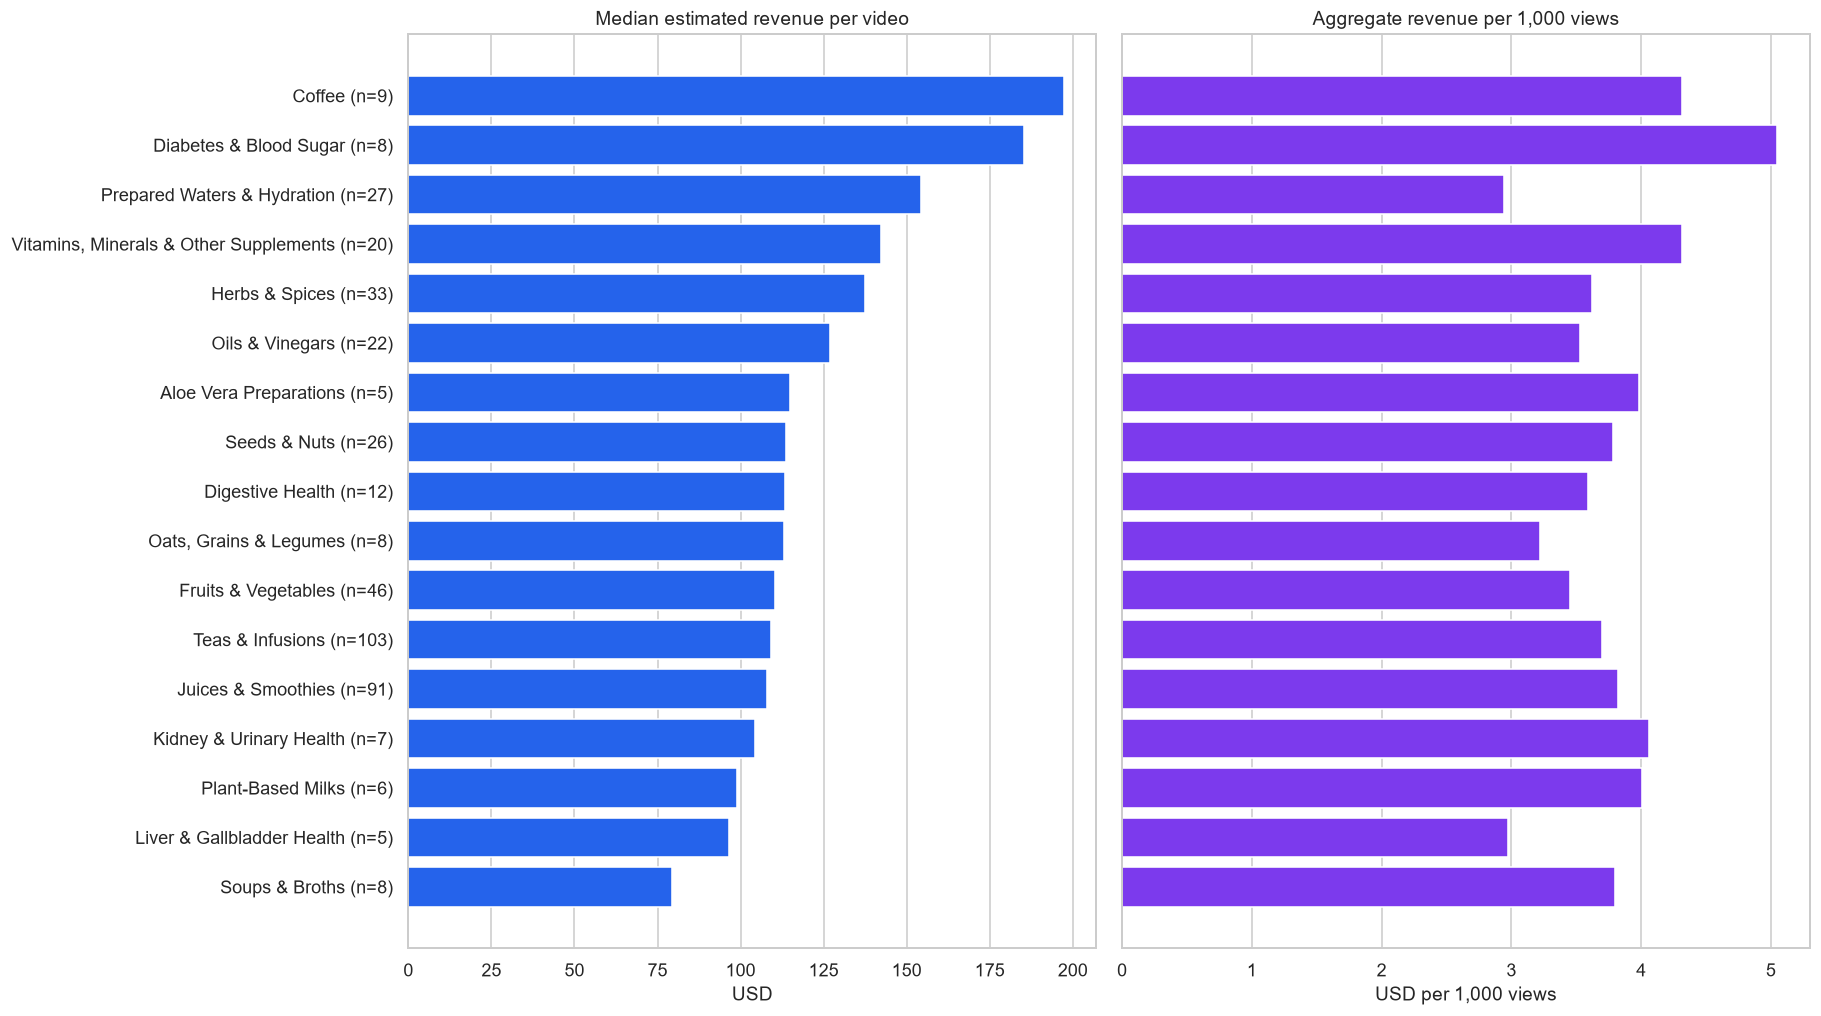

In [26]:
monetization_plot = (
    category_monetization
    .loc[category_monetization["video_count"] >= 5]
    .sort_values("median_revenue_usd", ascending=True)
    .copy()
)

labels = (
    monetization_plot["content_category"]
    + " (n="
    + monetization_plot["video_count"].astype(str)
    + ")"
)

fig, axes = plt.subplots(
    1, 2, figsize=(16, 9), sharey=True
)

axes[0].barh(
    labels,
    monetization_plot["median_revenue_usd"],
    color="#2563eb"
)
axes[0].set(
    title="Median estimated revenue per video",
    xlabel="USD"
)

axes[1].barh(
    labels,
    monetization_plot["revenue_per_1000_views_usd"],
    color="#7c3aed"
)
axes[1].set(
    title="Aggregate revenue per 1,000 views",
    xlabel="USD per 1,000 views"
)

for ax in axes:
    ax.set_xlim(left=0)
    ax.grid(axis="y", visible=False)

finish_plot("07_category_monetization")

### Findings — Category monetization

Among categories with at least five videos, **Coffee** has the highest
median estimated revenue per video, followed by **Diabetes & Blood Sugar**.

**Diabetes & Blood Sugar** leads in aggregate estimated revenue per
1,000 views at approximately **USD 5.05**. Coffee and Vitamins, Minerals
& Other Supplements each generate approximately **USD 4.31**.

**Prepared Waters & Hydration** ranks third in median revenue per video,
despite a lower aggregate revenue ratio of approximately **USD 2.95 per
1,000 views**. This illustrates why revenue per video and revenue relative
to views answer different questions.

**Business implication:** Evaluate reach and monetization together when
selecting topics for further testing. A category can generate substantial
revenue through higher view volume without leading in revenue per
1,000 views.

**Limitations:** These are descriptive estimates, not profit measures.
The aggregate ratio is weighted by views and can be influenced by highly
viewed videos. Differences in audience, publication timing, and other
monetization conditions have not been controlled.

### Category performance by publication year

We compare median views within publication-year groups to explore
whether category rankings differ across these groups.

Views refer to the exported metrics for videos published in each year,
not views earned during that calendar year. Video counts accompany
each median because category coverage varies by year.

Grouping by publication year does not equalize exposure time or
establish changes in channel performance.

In [27]:
category_year_summary = (
    videos_clean
    .groupby(["publish_year", "content_category"])
    .agg(
        video_count=("video_id", "size"),
        median_views=("views", "median"),
        median_revenue_usd=("estimated_revenue_usd", "median")
    )
    .reset_index()
    .sort_values(
        ["publish_year", "median_views"],
        ascending=[True, False]
    )
)

with pd.option_context("display.max_rows", None):
    display(category_year_summary.round(2))

,publish_year,content_category,video_count,median_views,median_revenue_usd
0,2024,Coffee,1,159705.0,930.98
11,2024,Prepared Waters & Hydration,1,81888.0,398.02
6,2024,Juices & Smoothies,4,59109.5,277.42
10,2024,Physical Activity & Sedentary Habits,1,48013.0,160.33
13,2024,Seeds & Nuts,1,47118.0,227.98
4,2024,Herbs & Spices,3,45440.0,104.73
15,2024,Sleep Health,1,44867.0,245.08
1,2024,Digestive Health,4,41778.0,202.21
16,2024,Teas & Infusions,6,35913.5,142.27
5,2024,Joint & Musculoskeletal Health,1,29336.0,30.61


### Median views by category within each publication year

Each chart includes categories with at least five videos published
in that year. Labels show the number of videos behind each median.

The same horizontal scale is used across charts to support visual
comparison. Categories may appear in one year and be absent in another
because their video counts fall below the display threshold.

Only Teas & Infusions meets the threshold in 2024, so that chart does
not provide a ranking across multiple categories.

These are publication-year groups, not views earned during each year.
Differences may reflect exposure time, content mix, and other conditions;
they should not be interpreted as annual growth or decline.

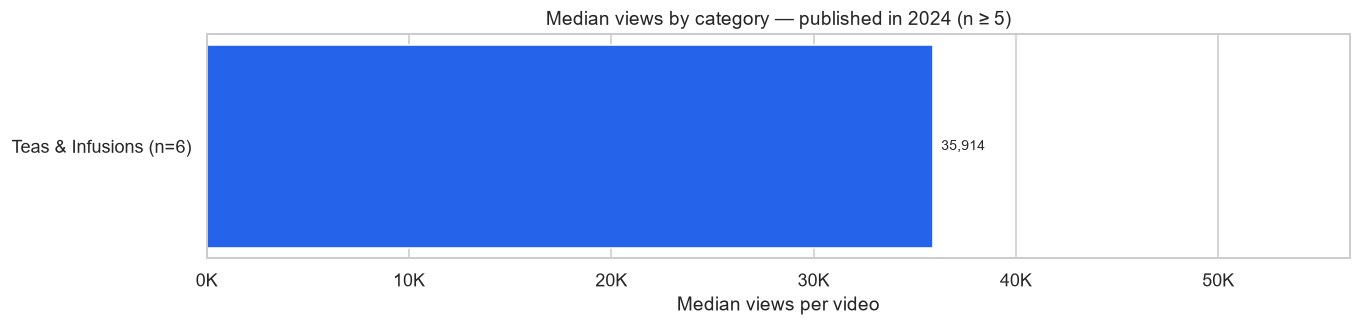

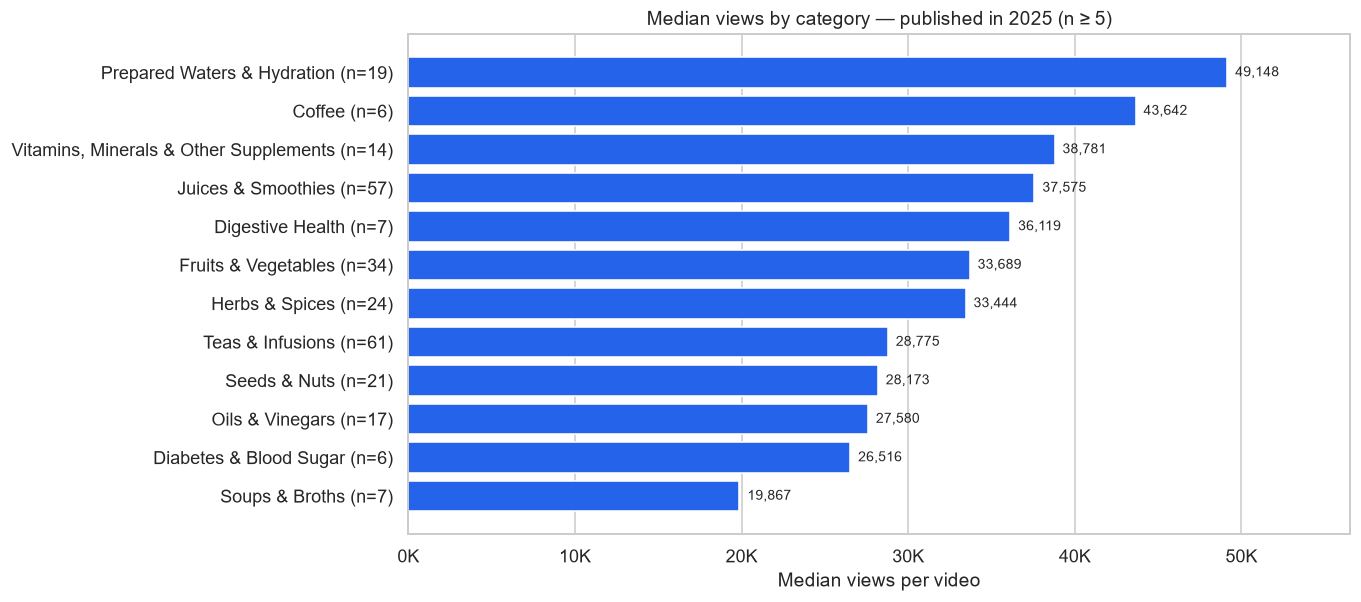

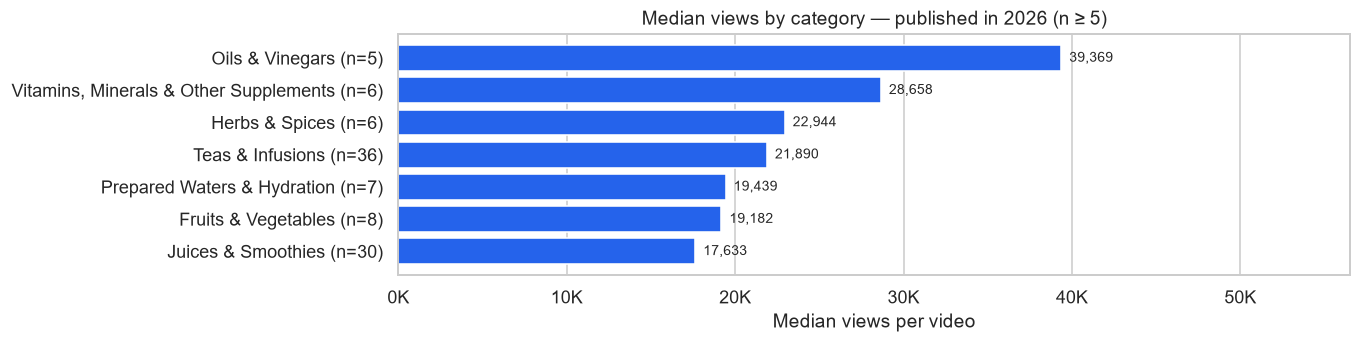

In [28]:
# Apply the minimum count within each year and category.
year_plot_data = category_year_summary.loc[
    category_year_summary["video_count"] >= 5
].copy()

# Use the same axis limit for every year.
shared_xmax = year_plot_data["median_views"].max() * 1.15

for year in sorted(category_year_summary["publish_year"].dropna().unique()):

    year_data = (
        year_plot_data
        .loc[year_plot_data["publish_year"] == year]
        .sort_values("median_views", ascending=True)
    )

    if year_data.empty:
        print(f"{year}: no categories with at least five videos.")
        continue

    labels = (
        year_data["content_category"]
        + " (n="
        + year_data["video_count"].astype(str)
        + ")"
    )

    fig, ax = plt.subplots(
        figsize=(12, max(3, len(year_data) * 0.45))
    )

    bars = ax.barh(
        labels,
        year_data["median_views"],
        color="#2563eb"
    )

    ax.bar_label(
        bars,
        labels=[f"{value:,.0f}" for value in year_data["median_views"]],
        padding=5,
        fontsize=9
    )

    ax.set(
        title=f"Median views by category — published in {year} (n ≥ 5)",
        xlabel="Median views per video",
        ylabel="",
        xlim=(0, shared_xmax)
    )

    ax.grid(axis="y", visible=False)

    finish_plot(f"08_category_median_views_{year}")

### Findings — Category performance by publication year

**2024: limited category coverage.**
Only Teas & Infusions meets the five-video threshold, with a median
of 35,913.5 views across six videos. It is the only eligible category,
not necessarily the best-performing category published that year.

**2025: Prepared Waters & Hydration leads the displayed categories.**
Its median reaches 49,148 views across 19 videos, followed by Coffee
at 43,641.5 views across six videos and Vitamins, Minerals & Other
Supplements at 38,781 views across 14 videos.

Juices & Smoothies combines a relatively high median of 37,575 views
with a larger group of 57 videos. Teas & Infusions has the largest
displayed group, with 61 videos, but a lower median of 28,775 views.

**2026: Oils & Vinegars leads, with a small group.**
Its median is 39,369 views across five videos, followed by Vitamins,
Minerals & Other Supplements at 28,658 views across six videos.
Both results warrant caution because of their limited sample sizes.

**Category rankings differ across publication-year groups.**
Prepared Waters & Hydration has a median of 49,148 views in the 2025
group versus 19,439 in the 2026 group. Oils & Vinegars shows the opposite
direction: 27,580 views in 2025 versus 39,369 in 2026.

These are comparisons between different sets of videos, not changes
in the same videos over time. The categories eligible for display
also differ between years.

**Business implication:** Use the overall category ranking together
with publication-year results when selecting topics for further testing.
A strong overall median does not guarantee a similar result in every
publication group.

**Limitations:** These metrics are not views earned during each calendar
year. Publication coverage, exposure time, content mix, and sample sizes
differ. Lower medians in newer publication groups do not by themselves
demonstrate declining audience interest or worsening channel performance.
A stronger follow-up would compare views within the same post-publication
window, such as each video's first 30 days.

## E — Execute: Findings, recommendations, and next steps

### Business objective

Analyze the exported long-form video dataset from Dr. Agustín Landívar's
YouTube channel to support content decisions for Dr. Landívar, the CEO,
and the content team.

The analysis covers 498 videos. Results describe this exported subset
and should not be presented as totals for the entire channel.

### Main findings

**1. Typical reach and total contribution tell different stories.**

Among categories with at least five videos, Prepared Waters & Hydration
and Digestive Health have the highest median views: 37,240 and 37,188.5,
respectively.

Teas & Infusions contributes the most total views, while Juices &
Smoothies contributes the most total estimated revenue. Their larger
publishing volumes and standout videos help explain these contributions.

**2. Category medians conceal substantial variation.**

Categories with similar medians can have different distributions.
Prepared Waters & Hydration shows greater relative variation in its
central results than Digestive Health.

Several categories contain exceptionally highly viewed videos.
These observations remain in the analysis because unusual performance
alone is not evidence of a data error.

**3. Reach and monetization should be evaluated together.**

Coffee has the highest median estimated revenue per video among the
displayed categories.

Diabetes & Blood Sugar has the highest aggregate estimated revenue
per 1,000 views, approximately USD 5.05. A higher revenue ratio does not
necessarily imply higher total revenue or higher profit.

**4. Category rankings vary across publication-year groups.**

Prepared Waters & Hydration leads the eligible 2025 categories, while
Oils & Vinegars leads in 2026, based on only five videos.

Only Teas & Infusions meets the five-video threshold in 2024.
These charts therefore compare different sets of eligible categories
and do not establish annual growth or decline.

### Recommended actions

1. **Develop content-test candidates.**
   Investigate Prepared Waters & Hydration and Digestive Health for
   typical reach, and Coffee and Diabetes & Blood Sugar for monetization.
   Treat these as candidates for testing, not guaranteed winners.

2. **Review standout videos individually.**
   Compare their subjects, titles, thumbnails, duration, and publication
   timing with more typical videos in the same category.

3. **Evaluate new videos over a consistent observation window.**
   Request first-30-day metrics so that newer and older publications
   can be compared at the same age.

4. **Track multiple outcomes.**
   Evaluate views, estimated revenue, revenue per 1,000 views, CTR,
   and viewing duration together. Avoid choosing topics from a single
   ranking.

5. **Maintain classification provenance.**
   Preserve the distinction between categories accepted from titles
   and categories assigned from supplied summaries. Revisit ambiguous
   assignments before using them for major production decisions.

### Limitations

- The reporting period, export filters, and selection criteria require
  confirmation before broader conclusions are drawn.
- Publication-year groups do not equalize exposure time.
- Categories represent editorial subjects and include both health
  topics and ingredient or preparation groups.
- Category assignments are not all independently verified against
  video content.
- Five videos is a descriptive display threshold, not a guarantee
  of representativeness or statistical significance.
- Correlations and category comparisons do not establish causation.
- Estimated revenue does not represent profit or product sales.

### Delivery plan

Validate the final video-level dataset and export its metrics,
selected categories, and classification status for Tableau.

Use the dashboard and executive summaries to communicate findings,
support content-test planning, and document remaining uncertainties.

### Final dataset validation before export

We verify that each video has a unique identifier, a selected category,
and the required analysis fields.

The export will retain individual video records, including categories
with fewer than five videos. The minimum-count rule applies only to
selected charts, not to the underlying dataset.

In [29]:
# Fields required for the Tableau dataset.
export_columns = [
    "video_id",
    "video_title",
    "video_url",
    "publish_date",
    "publish_year",
    "publish_month",
    "publish_day_of_week",
    "video_duration_seconds",
    "video_duration_minutes",
    "views",
    "impressions",
    "impressions_ctr_percent",
    "new_viewers",
    "returning_viewers",
    "casual_viewers",
    "regular_viewers",
    "estimated_revenue_usd",
    "average_view_duration_seconds",
    "average_view_duration_percent",
    "estimated_revenue_per_1000_views_usd",
    "content_category",
    "review_status",
    "classification_note"
]

# Check that all required columns exist.
missing_columns = [
    column for column in export_columns
    if column not in videos_clean.columns
]
assert not missing_columns, f"Missing columns: {missing_columns}"

# Check identifiers and category coverage.
assert len(videos_clean) == 498, "Unexpected video count."
assert videos_clean["video_id"].notna().all()
assert videos_clean["video_id"].str.strip().ne("").all()
assert videos_clean["video_id"].is_unique

assert not (
    videos_clean["content_category"]
    .fillna("")
    .str.strip()
    .isin(["", "Unclassified"])
    .any()
), "Some videos still need a category."

# Create the export table without changing the analysis dataset.
tableau_data = videos_clean[export_columns].copy()

print("Videos:", len(tableau_data))
print("Columns:", len(tableau_data.columns))
print("Categories:", tableau_data["content_category"].nunique())
print("Total views:", f"{tableau_data['views'].sum():,.0f}")
print(
    "Total estimated revenue (USD):",
    f"{tableau_data['estimated_revenue_usd'].sum():,.2f}"
)

display(
    tableau_data.isna()
    .sum()
    .rename("missing_values")
    .to_frame()
)

display(tableau_data["review_status"].value_counts())

Videos: 498
Columns: 23
Categories: 42
Total views: 25,048,026
Total estimated revenue (USD): 91,752.29


,missing_values
video_id,0
video_title,0
video_url,0
publish_date,0
publish_year,0
publish_month,0
publish_day_of_week,0
video_duration_seconds,0
video_duration_minutes,0
views,0


review_status
Accepted from title               494
Assigned from supplied summary      4
Name: count, dtype: int64

### Export the validated dataset for Tableau

The export contains 498 video-level records, 23 fields, and 42 selected
content categories. No null values were detected in the selected fields.

Classification provenance is preserved: 494 categories were accepted
from titles and four were assigned from supplied summaries.

All videos are retained, including those in categories with fewer than
five videos. Dates are exported in ISO format, and numeric precision
is preserved for downstream calculations.

In [30]:
# Save the complete video-level dataset.
export_path = processed_dir / "youtube_long_form_tableau.csv"

tableau_data.to_csv(
    export_path,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# Preserve the category decisions separately.
category_review.to_csv(
    processed_dir / "long_form_categories_reviewed_v2.csv",
    index=False,
    encoding="utf-8-sig"
)

# Read the exported dataset back to verify the saved file.
export_check = pd.read_csv(
    export_path,
    dtype={"video_id": "string"},
    encoding="utf-8-sig"
)

assert export_check.shape == tableau_data.shape
assert export_check.columns.tolist() == export_columns
assert export_check["video_id"].tolist() == tableau_data["video_id"].tolist()
assert export_check["content_category"].tolist() == (
    tableau_data["content_category"].tolist()
)
assert export_check["views"].sum() == tableau_data["views"].sum()
assert np.isclose(
    export_check["estimated_revenue_usd"].sum(),
    tableau_data["estimated_revenue_usd"].sum(),
    rtol=0,
    atol=0.000001
)

print("Export verified successfully.")
print("Tableau file:", export_path.resolve())
print("Rows:", len(export_check))
print("Columns:", len(export_check.columns))

Export verified successfully.
Tableau file: C:\Users\USUARIO1\Documents\youtube-long-form-performance-analysis\data\processed\youtube_long_form_tableau.csv
Rows: 498
Columns: 23
